<a href="https://colab.research.google.com/github/gaudensiacharity22-maker/BWM-XMD-GO/blob/main/COU07506_Week02_240242471860.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COU 07506 – DIGITAL SIGNAL PROCESSING

## WEEK 2 – LAB 1A
### Setting Up the DSP Laboratory

**Name:** GAUDENSIA CHARITY MGAYA
**Registration Number:** 240242471860  
**Date:** 23 November 2026  
**Group:** GROUP 13

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

print("Week 2 Lab 1A is ready!")

Week 2 Lab 1A is ready!


Task 2.1:Aliasing of sinusoid

In [ ]:

f0 = 7.0
fs = 10.0

t = np.linspace(0, 1, 2000)
n = np.arange(0, int(fs) + 1)
tn = n / fs

print("Signal frequency:", f0, "Hz")
print("Sampling frequency:", fs, "Hz")

Signal frequency: 7.0 Hz
Sampling frequency: 10.0 Hz


Task 2.1 — Alias Frequency

In [ ]:

f_alias = abs(f0 - fs * round(f0/fs))

print("Original frequency:", f0, "Hz")
print("Alias frequency:", f_alias, "Hz")

Original frequency: 7.0 Hz
Alias frequency: 3.0 Hz


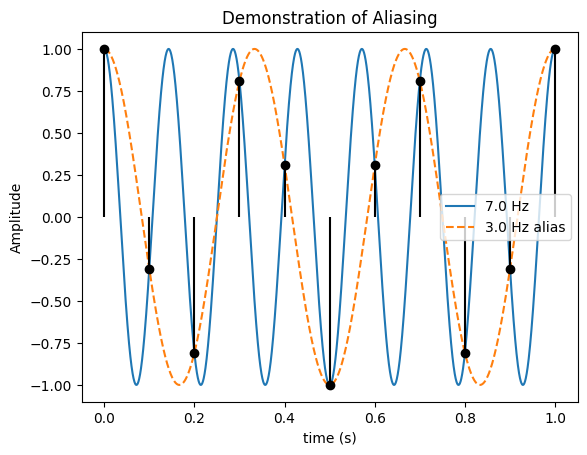

In [ ]:

plt.plot(t, np.cos(2*np.pi*f0*t), label=f"{f0} Hz")
plt.plot(t, np.cos(2*np.pi*f_alias*t), "--",
         label=f"{f_alias} Hz alias")

plt.stem(tn, np.cos(2*np.pi*f0*tn),
         linefmt="k-", markerfmt="ko", basefmt=" ")

plt.xlabel("time (s)")
plt.ylabel("Amplitude")
plt.title("Demonstration of Aliasing")
plt.legend()
plt.show()

Task 2.1 — Change Sampling Frequency

In [ ]:

sampling_rates = [12, 14, 20]

for fs_new in sampling_rates:
    alias = abs(f0 - fs_new * round(f0/fs_new))
    print("Sampling frequency:", fs_new, "Hz",
          "| Alias frequency:", alias, "Hz")

Sampling frequency: 12 Hz | Alias frequency: 5.0 Hz
Sampling frequency: 14 Hz | Alias frequency: 7.0 Hz
Sampling frequency: 20 Hz | Alias frequency: 7.0 Hz



Observation:

The experiment demonstrates that aliasing occurs when a signal is sampled at a frequency that is insufficient to represent its original frequency correctly. The 7 Hz signal appeared as 3 Hz when sampled at 10 Hz and as 5 Hz when sampled at 12 Hz. When sampled at 14 Hz and 20 Hz, it appeared as 7 Hz.

Conclusion:

The experiment shows that the sampling frequency affects the observed frequency of a signal. To avoid aliasing, the sampling frequency should be at least twice the highest frequency component of the original signal (Nyquist criterion).

2.2 — Hearing Aliasing.

In [ ]:

fs = 44100

t = np.arange(0, 3, 1/fs)

x = 0.5 * signal.chirp(
    t,
    f0=200,
    t1=3,
    f1=15000
)

print("Audio signal created successfully!")
print("Sampling frequency:", fs, "Hz")
print("Duration:", len(x)/fs, "seconds")

Audio signal created successfully!
Sampling frequency: 44100 Hz
Duration: 3.0 seconds


Task 2.2 — Downsampling

In [ ]:

for k in [2, 4, 8]:
    naive = x[::k]
    proper = signal.decimate(x, k, ftype="fir")

    print("k =", k)
    print("New sampling frequency =", fs // k, "Hz")
    print("--------------------------------")

k = 2
New sampling frequency = 22050 Hz
--------------------------------
k = 4
New sampling frequency = 11025 Hz
--------------------------------
k = 8
New sampling frequency = 5512 Hz
--------------------------------


Task 2.2 — Audio listening

In [ ]:

from IPython.display import Audio, display

k = 2

naive = x[::k]
proper = signal.decimate(x, k, ftype="fir")

print("Audio WITHOUT anti-aliasing filter:")
display(Audio(naive, rate=fs//k))

print("Audio WITH anti-aliasing filter:")
display(Audio(proper, rate=fs//k))

Audio WITHOUT anti-aliasing filter:


Audio WITH anti-aliasing filter:


Task 2.2 - k = 8

In [ ]:

k = 8

naive = x[::k]
proper = signal.decimate(x, k, ftype="fir")

print("WITHOUT anti-aliasing filter:")
display(Audio(naive, rate=fs//k))

print("WITH anti-aliasing filter:")
display(Audio(proper, rate=fs//k))

WITHOUT anti-aliasing filter:


WITH anti-aliasing filter:



Observation:

When the audio signal was downsampled without an anti-aliasing filter, distortion occurred due to aliasing. When an anti-aliasing filter was applied before downsampling, unwanted high-frequency components were reduced, resulting in a cleaner audio signal.

Conclusion:

An anti-aliasing filter is important in digital signal processing because it reduces unwanted high-frequency components before downsampling, helping to prevent aliasing.

Task 2.3 — Uniform Quantizer
           quantizer function.

In [ ]:

def quantize(x, bits, full_scale=1.0):
    delta = 2*full_scale / 2**bits
    q = np.round(x/delta)*delta
    return np.clip(q, -full_scale, full_scale - delta)

print("Quantizer function created successfully!")

Quantizer function created successfully!


Task 2.3 — sine signal

In [ ]:

fs = 8000

t = np.arange(0, 0.01, 1/fs)

x = 0.99*np.sin(2*np.pi*300*t)

xq = quantize(x, 3)

print("Original signal created!")
print("Quantized signal created!")
print("Number of samples:", len(x))

Original signal created!
Quantized signal created!
Number of samples: 80


Task 2.3 — Graph

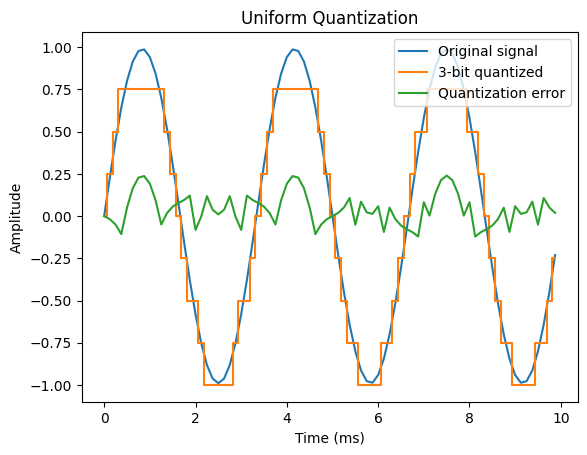

In [ ]:

plt.plot(t*1e3, x, label="Original signal")
plt.step(t*1e3, xq, where="mid", label="3-bit quantized")
plt.plot(t*1e3, x-xq, label="Quantization error")

plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.title("Uniform Quantization")
plt.legend()
plt.show()


Observation:

The original sine wave was converted into discrete amplitude levels using a 3-bit uniform quantizer. The quantized signal appeared as a staircase waveform. The difference between the original and quantized signals represents quantization error.

Conclusion:

Uniform quantization converts continuous amplitude values into a finite number of discrete levels. Increasing the number of bits increases the number of quantization levels and reduces quantization error.

Task 2.4 — Verify the 6 dB per Bit Rule.
Bit values

In [ ]:

bits = np.arange(2, 17, 2)

print("Bits used:", bits)

Bits used: [ 2  4  6  8 10 12 14 16]


Task 2.4 — Measuring SQNR

In [ ]:

meas = [
    10*np.log10(
        np.sum(x**2) /
        np.sum((x - quantize(x, B))**2)
    )
    for B in bits
]

print("Measured SQNR:")
print(meas)

Measured SQNR:
[np.float64(9.601454182214168), np.float64(23.57671212071331), np.float64(36.81117032372333), np.float64(48.93266972314613), np.float64(62.808012346768166), np.float64(72.8359827219283), np.float64(88.13252320131404), np.float64(98.90533146415073)]


Task 2.4 — Comparison graph

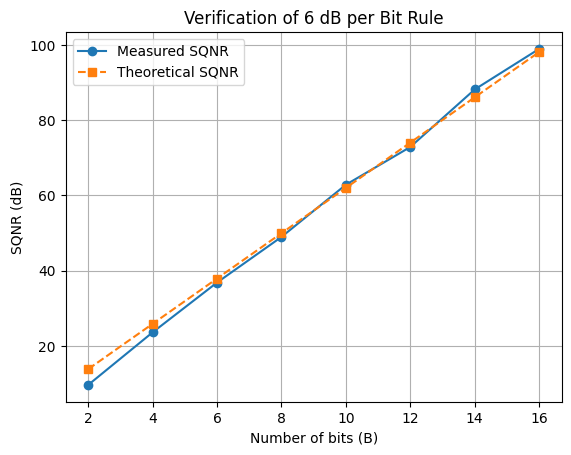

In [ ]:

theoretical = 6.02*bits + 1.76

plt.plot(bits, meas, "o-", label="Measured SQNR")
plt.plot(bits, theoretical, "s--", label="Theoretical SQNR")

plt.xlabel("Number of bits (B)")
plt.ylabel("SQNR (dB)")
plt.title("Verification of 6 dB per Bit Rule")
plt.legend()
plt.grid()
plt.show()


Observation:

The measured SQNR increased as the number of quantization bits increased. The measured results showed a trend similar to the theoretical SQNR calculated using the formula SQNR = 6.02B + 1.76 dB.

Conclusion:

The experiment verifies the 6 dB per bit rule. Increasing the quantization resolution by one bit improves the SQNR by approximately 6 dB for a full-scale sinusoidal signal.

Task 2.5 —Voice Quantizion

In [ ]:

fs_voice = 44100

t_voice = np.arange(0, 3, 1/fs_voice)

voice_signal = 0.5 * signal.chirp(
    t_voice,
    f0=200,
    t1=3,
    f1=15000
)

print("Audio signal ready for quantization!")

Audio signal ready for quantization!


Task 2.5 — Quantization for 4, 8 and 12 bits

In [ ]:

q4 = quantize(voice_signal, 4)
q8 = quantize(voice_signal, 8)
q12 = quantize(voice_signal, 12)

print("4-bit quantization completed!")
print("8-bit quantization completed!")
print("12-bit quantization completed!")

4-bit quantization completed!
8-bit quantization completed!
12-bit quantization completed!


Task 2.5 — Audio listening

In [ ]:

print("4-bit audio:")
display(Audio(q4, rate=fs_voice))

print("8-bit audio:")
display(Audio(q8, rate=fs_voice))

print("12-bit audio:")
display(Audio(q12, rate=fs_voice))

4-bit audio:


8-bit audio:


12-bit audio:


Task 2.5 — Calculating SQNR

In [ ]:

sqnr_4 = 10*np.log10(
    np.sum(voice_signal**2) /
    np.sum((voice_signal - q4)**2)
)

sqnr_8 = 10*np.log10(
    np.sum(voice_signal**2) /
    np.sum((voice_signal - q8)**2)
)

sqnr_12 = 10*np.log10(
    np.sum(voice_signal**2) /
    np.sum((voice_signal - q12)**2)
)

print("4-bit SQNR:", sqnr_4, "dB")
print("8-bit SQNR:", sqnr_8, "dB")
print("12-bit SQNR:", sqnr_12, "dB")

4-bit SQNR: 20.357670100675634 dB
8-bit SQNR: 44.049735869523985 dB
12-bit SQNR: 68.01153646422586 dB



Observation:

The SQNR increased as the number of quantization bits increased from 4 bits to 8 bits and 12 bits. This indicates that quantization noise decreases as the number of bits increases.

Conclusion:

Higher bit resolution provides better representation of the original audio signal and reduces quantization noise. Therefore, a 12-bit quantizer generally provides better signal quality than 8-bit and 4-bit quantizers.

Note: A simulated chirp signal was used instead of the personal voice recording because the original audio file had a format problem.